# 2.1.2 如何估计 f？
依据手稿第4—5页整理。按顺序运行。数据用于说明模型调用流程。


## 代码块1：导入工具
NumPy用于创建数组；两个模型类分别用于线性回归与KNN回归。


In [2]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor


## 代码块2：准备手稿中的数据
保留手稿中的五条训练记录和新输入25。X_train的每一行是一条记录，每一列是一个特征；y_train是一维数组。


In [3]:
X_train = np.array([[10.0], [20.0], [30.0], [40.0], [50.0]])
y_train = np.array([4.0, 7.0, 8.0, 11.0, 12.0])
X_new = np.array([[25.0]])
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_new shape:", X_new.shape)


X_train shape: (5, 1)
y_train shape: (5,)
X_new shape: (1, 1)


## 代码块3：创建并训练线性回归模型
先创建模型，再调用fit，把训练输入和目标交给模型。


In [4]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)


LinearRegression()

## 代码块4：查看学到的参数
intercept_是截距；coef_是特征系数数组。


In [5]:
print("Intercept:", linear_model.intercept_)
print("Coefficients:", linear_model.coef_)


Intercept: 2.3999999999999995
Coefficients: [0.2]


## 代码块5：对新输入作线性回归预测
predict使用刚才训练好的模型；X_new仍保持二维。


In [6]:
linear_prediction = linear_model.predict(X_new)
print("Linear prediction:", linear_prediction)


Linear prediction: [7.4]


## 代码块6：创建并训练KNN回归模型
沿用手稿的设置：n_neighbors=2，使用两个邻居。


In [7]:
knn_model = KNeighborsRegressor(n_neighbors=2)
knn_model.fit(X_train, y_train)


KNeighborsRegressor(n_neighbors=2)

## 代码块7：对同一输入作KNN预测
沿用手稿的调用顺序，使用predict预测，并打印返回的数组。


In [8]:
knn_prediction = knn_model.predict(X_new)
print("KNN prediction:", knn_prediction)


KNN prediction: [7.5]


## 为图形准备连续的输入位置
np.linspace在训练输入的范围内取201个位置；reshape(-1, 1)将它们整理成一列。两次predict使用已经训练好的模型，不重新训练。


In [9]:
import matplotlib.pyplot as plt
from pathlib import Path

X_grid = np.linspace(10.0, 50.0, 201).reshape(-1, 1)
linear_curve = linear_model.predict(X_grid)
knn_curve = knn_model.predict(X_grid)


## 画图、保存并显示
散点是手稿中的五条记录，两条线是模型在各输入位置的预测；竖虚线标出新输入25。图片保存到当前Notebook所在目录的“图片”子目录。


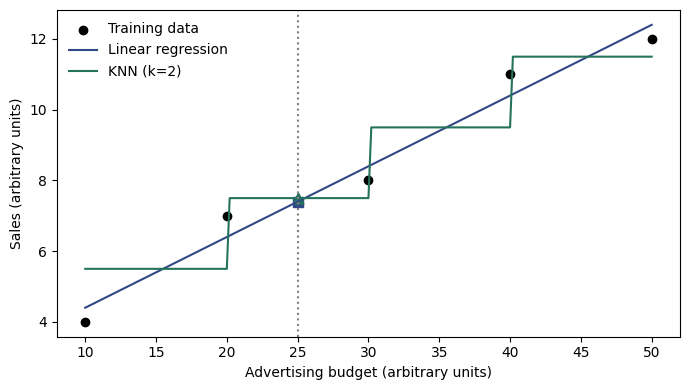

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(X_train[:, 0], y_train, color="black", label="Training data")
ax.plot(X_grid[:, 0], linear_curve, color="#314887", label="Linear regression")
ax.plot(X_grid[:, 0], knn_curve, color="#24735A", label="KNN (k=2)")
ax.axvline(X_new[0, 0], color="gray", linestyle=":")
ax.scatter(X_new[:, 0], linear_prediction, color="#314887", marker="s", s=60)
ax.scatter(X_new[:, 0], knn_prediction, color="#24735A", marker="^", s=60)
ax.set_xlabel("Advertising budget (arbitrary units)")
ax.set_ylabel("Sales (arbitrary units)")
ax.legend(frameon=False)
fig.tight_layout()

image_dir = Path("图片")
image_dir.mkdir(exist_ok=True)
fig.savefig(image_dir / "212-linear-knn.pdf", bbox_inches="tight")
fig.savefig(image_dir / "212-linear-knn.png", dpi=180, bbox_inches="tight")
plt.show()
